In [1]:
from modules.benchmark import *
from catboost import CatBoostClassifier

# CatBoost

In [2]:
visco = quick_load(feature='expert_chen', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

In [7]:
X[['type_surfactant1', 'type_surfactant2']] = X[['type_surfactant1', 'type_surfactant2']].fillna('None')

In [8]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 91 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   type_surfactant1                    8185 non-null   object 
 1   c_surfactant1                       8185 non-null   float64
 2   type_surfactant2                    8185 non-null   object 
 3   c_surfactant2                       8185 non-null   float64
 4   c_additive1                         8185 non-null   float64
 5   c_additive2                         8185 non-null   float64
 6   temperature                         8185 non-null   int64  
 7   surfactant1_chen_MolLogP            8185 non-null   float64
 8   surfactant1_chen_Chi1v              8185 non-null   float64
 9   surfactant1_chen_VSA_EState7        8185 non-null   float64
 10  surfactant1_chen_VSA_EState8        8185 non-null   float64
 11  surfactant1_chen_qed                8185 no

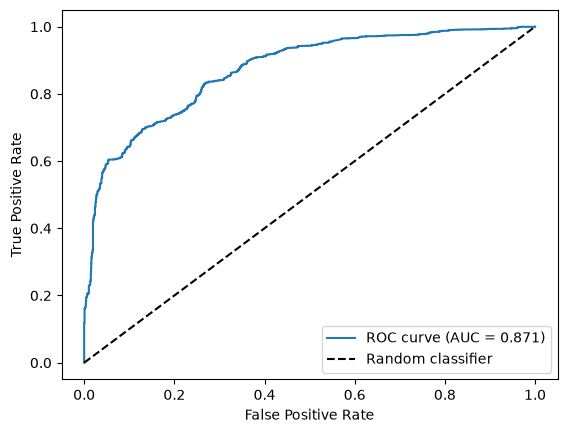

In [9]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']

model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    random_seed=42,
    verbose=0
)

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba", params={'cat_features': categorical_features})[:,1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [10]:
roc_auc

0.8711636621798049

# Avalon

In [11]:
visco = quick_load(feature='avalon', columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)
X[['type_surfactant1', 'type_surfactant2']] = X[['type_surfactant1', 'type_surfactant2']].fillna('None')

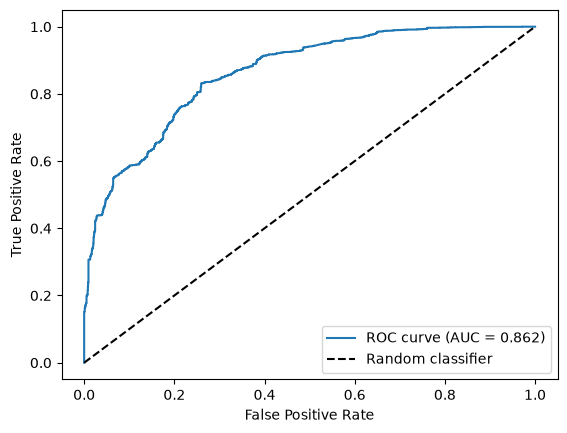

In [12]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']

model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    random_seed=42,
    verbose=0
)

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba", params={'cat_features': categorical_features})[:,1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [13]:
roc_auc

0.8623927586238478